# Week 8 — Ensemble Methods: Random Forest with Molecular Properties

## Combining many trees into one prediction

This notebook adapts the Week 8 Random Forest lesson to `properties.csv`.

**Task:** classify compounds into two groups using Mannhold LogP:
- `0`: Mannhold LogP at or below the dataset median (2.45)
- `1`: Mannhold LogP above the median

A Random Forest combines many decision trees. Each tree is trained on a bootstrap sample, and each split considers a random subset of features. The trees vote to produce the final prediction.

This is a classification exercise about LogP categories. It does **not** predict biological activity because the dataset has no bioactivity outcome labels.

**Before running:** put this notebook and `properties(1).csv` in the same folder, or update `DATA_PATH` below.

## 1. Prepare the data

We use numeric molecular descriptors as inputs and create the same high/low Mannhold LogP target as the evaluation notebook.

We exclude identifiers, molecule names, the target itself, and `XLogP` (another LogP estimate). Selected descriptor columns are converted to numeric values. Missing descriptor values are imputed using the median.

We keep 20% of the data aside as a test set. All model comparison and settings checks use cross-validation on the training set.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
DATA_PATH = r"C:\COLLEGE\CSC1171\Week 1\week3-DataIntro\notebooks\properties.csv"  # Keep the CSV in the same folder as this notebook.

feature_names = ['Molecular Weight', 'Topological Polar Surface Area', 'Hydrogen Bond Acceptors', 'Hydrogen Bond Donors', 'Rotatable Bonds Count', 'Aromatic Atoms Count', 'Aromatic Bonds Count', 'Bond Count', 'Largest Chain', 'Largest Pi Chain', 'SP3 Character', 'Formal Charge', 'Zagreb Index']

df = pd.read_csv(DATA_PATH)
for col in feature_names:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Mannhold LogP"]).copy()
logp_cutoff = df["Mannhold LogP"].median()
X = df[feature_names].copy()
y = (df["Mannhold LogP"] > logp_cutoff).astype(int)

print("Rows:", len(df))
print(f"Mannhold LogP median cutoff: {logp_cutoff:.2f}")
print("Class counts (0 = lower/equal, 1 = higher):")
print(y.value_counts().sort_index())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows (held aside):", len(X_test))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).sort_index())



Rows: 15166
Mannhold LogP median cutoff: 2.45
Class counts (0 = lower/equal, 1 = higher):
Mannhold LogP
0    7874
1    7292
Name: count, dtype: int64
Training rows: 12132 | Test rows (held aside): 3034
Training class proportions:


Mannhold LogP
0    0.519205
1    0.480795
Name: proportion, dtype: float64

About half the compounds are in each class because the median is the cutoff. Class 1 means higher Mannhold LogP. We still report precision, recall and F1 as well as accuracy so that performance on both classes is visible.

## 2. Train a Random Forest

Main settings:
- `n_estimators`: number of trees in the forest.
- `max_features="sqrt"`: each split considers roughly the square root of the number of input features.
- `bootstrap=True`: each tree trains on a sample drawn with replacement.
- `random_state`: makes the random process reproducible.

We impute missing values before fitting the forest. The imputer is fitted on the training data only.

In [5]:
# Fit the imputer on training data only, then transform train and test.
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=feature_names, index=X_train.index
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test),
    columns=feature_names, index=X_test.index
)

forest = RandomForestClassifier(
    n_estimators=200,
    max_features="sqrt",
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
forest.fit(X_train_imp, y_train)
print("Number of trees in the forest:", len(forest.estimators_))

Number of trees in the forest: 200


## 3. Inside the forest: trees can disagree, then the forest votes

Each tree sees a different bootstrap sample and considers random subsets of descriptors. Therefore, trees may make different predictions for the same compound.

The table below shows the predictions from the first five trees for training examples where those five trees do not all agree, alongside the prediction from the full forest.

In [6]:
# Predictions from the first five trees, plus the full forest prediction.
votes = pd.DataFrame(
    {f"tree {i}": tree.predict(X_train_imp).astype(int)
     for i, tree in enumerate(forest.estimators_[:5], start=1)},
    index=X_train.index
)
votes["forest (all 200 trees)"] = forest.predict(X_train_imp)

# Show training rows where the first five trees disagree.
disagreements = votes[votes.iloc[:, :5].nunique(axis=1) > 1]
display(disagreements.head())

c:\Users\aloug\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\aloug\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\aloug\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\aloug\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\aloug\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


,tree 1,tree 2,tree 3,tree 4,tree 5,forest (all 200 trees)
10989,1,1,1,1,0,1
10800,0,0,0,0,1,0
12103,0,1,1,1,1,0
11165,1,0,0,0,0,0
6649,1,1,1,0,1,1


## 4. Evaluate with cross-validation

A forest can fit its training data very closely, so training accuracy is not a fair measure of performance on new compounds.

We use 5-fold stratified cross-validation on the training set. We report the mean and standard deviation for accuracy, precision, recall and F1. The test set remains untouched.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metrics = ["accuracy", "precision", "recall", "f1"]

# Keep imputation inside the pipeline so it is refitted within each CV fold.
forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200, max_features="sqrt", bootstrap=True,
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])

scores = cross_validate(
    forest_pipeline, X_train, y_train, cv=cv, scoring=metrics,
    return_train_score=False
)

cv_summary = pd.DataFrame({
    "mean": [scores[f"test_{m}"].mean() for m in metrics],
    "SD": [scores[f"test_{m}"].std() for m in metrics],
}, index=metrics)
display(cv_summary.round(3))

,mean,SD
accuracy,0.955,0.003
precision,0.938,0.006
recall,0.971,0.003
f1,0.954,0.002


## 5. How many trees are enough?

More trees can make the forest's predictions more stable, but the improvement usually levels off while training time continues to increase.

We compare the mean cross-validated F1 score for forests with different numbers of trees. Small fluctuations can occur because of the particular folds.

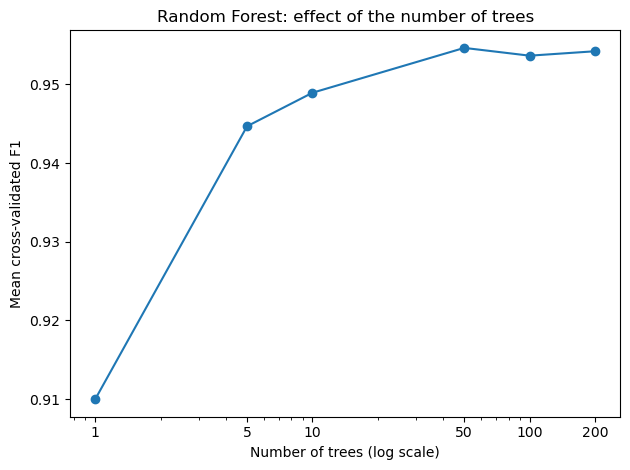

,Number of trees,Mean CV F1
0,1,0.910
1,5,0.945
2,10,0.949
3,50,0.955
4,100,0.954
5,200,0.954


In [8]:
tree_counts = [1, 5, 10, 50, 100, 200]
f1_by_size = []

for n in tree_counts:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("forest", RandomForestClassifier(
            n_estimators=n, max_features="sqrt",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
    f1 = cross_validate(
        model, X_train, y_train, cv=cv, scoring="f1",
        return_train_score=False
    )["test_score"]
    f1_by_size.append(f1.mean())

plt.plot(tree_counts, f1_by_size, marker="o")
plt.xscale("log")
plt.xticks(tree_counts, tree_counts)
plt.xlabel("Number of trees (log scale)")
plt.ylabel("Mean cross-validated F1")
plt.title("Random Forest: effect of the number of trees")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"Number of trees": tree_counts,
                      "Mean CV F1": f1_by_size}).round(3))

## 6. Which molecular descriptors does the forest rely on?

Feature importance summarises how much each descriptor reduces impurity across the forest's decision splits. The importances sum to 1.

These values describe which features the fitted model relies on. They do **not** show that a feature causes LogP to change. Importance can also be shared between correlated descriptors.

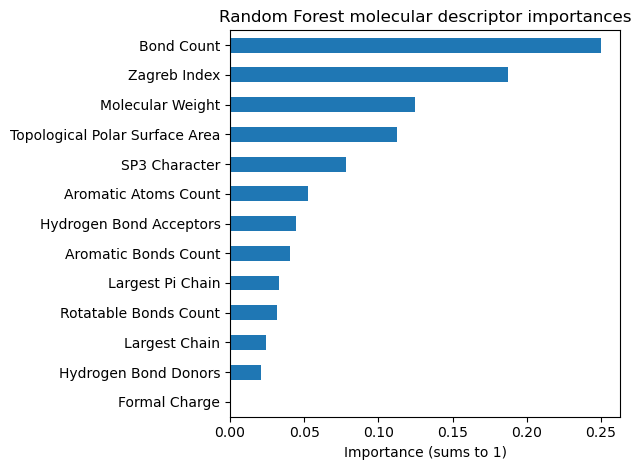

,Importance
Bond Count,0.250
Zagreb Index,0.187
Molecular Weight,0.124
Topological Polar Surface Area,0.112
SP3 Character,0.078
Aromatic Atoms Count,0.052
Hydrogen Bond Acceptors,0.045
Aromatic Bonds Count,0.040
Largest Pi Chain,0.033
Rotatable Bonds Count,0.032


In [9]:
importances = pd.Series(
    forest.feature_importances_, index=feature_names
).sort_values()

importances.plot.barh()
plt.xlabel("Importance (sums to 1)")
plt.title("Random Forest molecular descriptor importances")
plt.tight_layout()
plt.show()

display(importances.sort_values(ascending=False).to_frame("Importance").round(3))

## 7. Final evaluation on the test set

We now evaluate the forest on the test set, which has not been used for model fitting or cross-validation.

The classification report gives precision, recall and F1 for each class. The confusion matrix shows the types of correct and incorrect predictions.

                  precision    recall  f1-score   support

Lower/equal LogP       0.97      0.94      0.96      1575
     Higher LogP       0.94      0.97      0.95      1459

        accuracy                           0.95      3034
       macro avg       0.95      0.96      0.95      3034
    weighted avg       0.95      0.95      0.95      3034



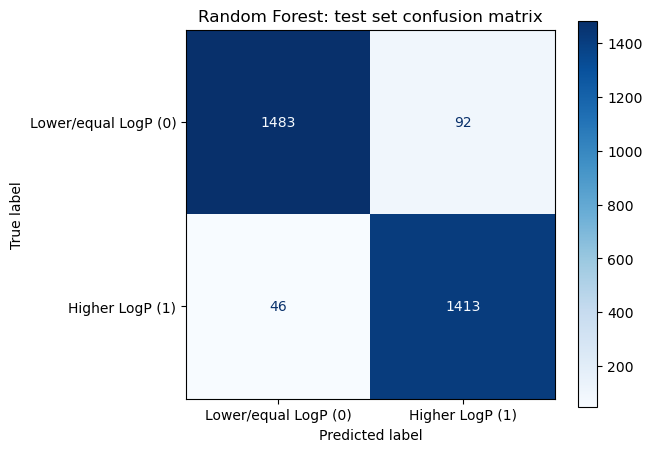

In [10]:
test_pred = forest.predict(X_test_imp)

print(classification_report(
    y_test, test_pred,
    target_names=["Lower/equal LogP", "Higher LogP"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["Lower/equal LogP (0)", "Higher LogP (1)"],
    cmap="Blues"
)
plt.title("Random Forest: test set confusion matrix")
plt.tight_layout()
plt.show()

## 8. Questions

1. Why can a Random Forest perform better than one decision tree?
2. What is the purpose of bootstrap sampling?
3. Why does the forest consider a random subset of features at each split?
4. What happens to the cross-validated F1 score as the number of trees increases?
5. Why are feature importances not evidence of causation?
6. Why is the test set kept separate until the final evaluation?

## Key takeaways

- A Random Forest combines many decision trees using voting.
- Bootstrap samples and random feature subsets make the trees less alike.
- Cross-validation gives a more stable estimate than one training score.
- Feature importance describes model reliance, not causation.
- The model predicts a LogP category, not bioactivity.